In [1]:
from PIL import Image, ImageOps
import numpy as np
import matplotlib.pyplot as plt

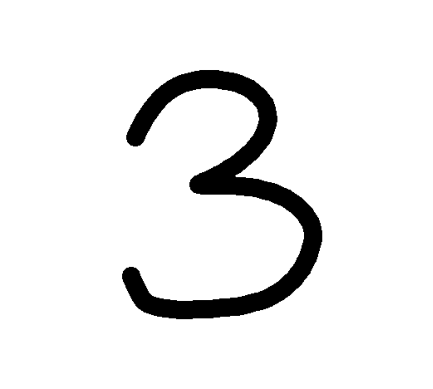

In [2]:
# Open handwritten digit image
image = Image.open("digit.png")

# Display image
plt.imshow(image)
plt.axis("off")
plt.show()

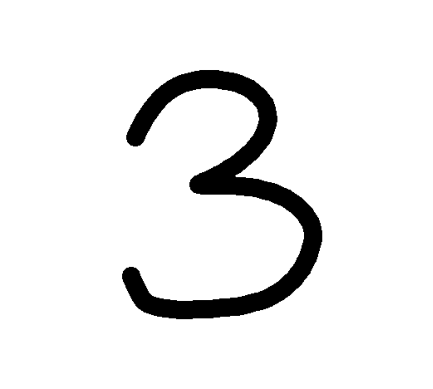

In [3]:
# Convert image to grayscale
image = image.convert("L")

# Display grayscale image
plt.imshow(image, cmap="gray")
plt.axis("off")
plt.show()

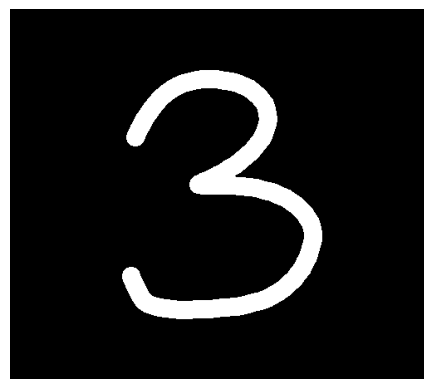

In [4]:
# Invert image colors
image = ImageOps.invert(image)

# Display inverted image
plt.imshow(image, cmap="gray")
plt.axis("off")
plt.show()

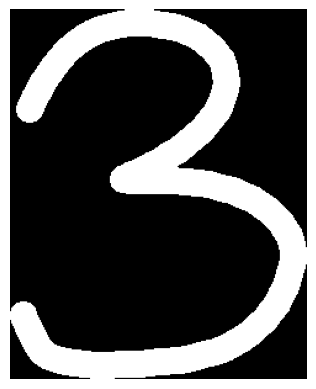

In [5]:
# Find the bounding box of the digit
bbox = image.getbbox()

# Crop the digit
image = image.crop(bbox)

# Display cropped image
plt.imshow(image, cmap="gray")
plt.axis("off")
plt.show()

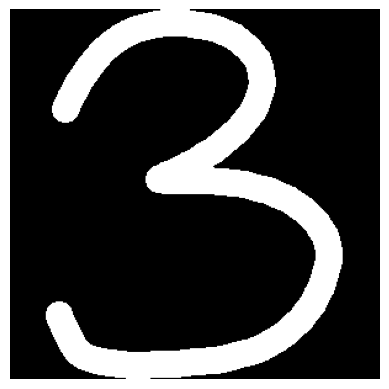

In [6]:
# Get image dimensions
width, height = image.size

# Find the larger dimension
max_size = max(width, height)

# Create a black square canvas
new_image = Image.new("L", (max_size, max_size), 0)

# Calculate center position
left = (max_size - width) // 2
top = (max_size - height) // 2

# Paste digit in the center
new_image.paste(image, (left, top))

# Display centered image
plt.imshow(new_image, cmap="gray")
plt.axis("off")
plt.show()

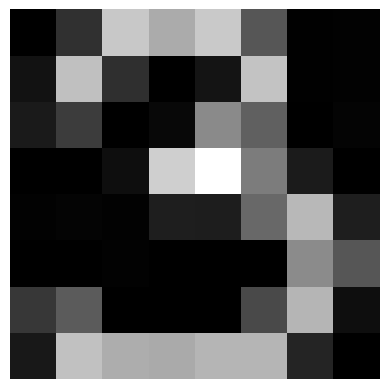

Image size: (8, 8)


In [7]:
# Resize image to 8x8
image = new_image.resize((8, 8), Image.Resampling.LANCZOS)

# Display resized image
plt.imshow(image, cmap="gray")
plt.axis("off")
plt.show()

print("Image size:", image.size)

In [8]:
# Convert image into NumPy array
image_array = np.array(image, dtype=np.float32)

# Normalize pixel values (0 to 1)
image_array = image_array / 255.0

print("Shape:", image_array.shape)
print("Minimum value:", image_array.min())
print("Maximum value:", image_array.max())

Shape: (8, 8)
Minimum value: 0.0
Maximum value: 0.84705883


In [9]:
import torch

# Convert NumPy array to PyTorch tensor
image_tensor = torch.tensor(image_array, dtype=torch.float32)

# Add batch dimension
image_tensor = image_tensor.unsqueeze(0)

# Add channel dimension for CNN
cnn_input = image_tensor.unsqueeze(0)

# ViT input
vit_input = image_tensor

print("CNN input shape:", cnn_input.shape)
print("ViT input shape:", vit_input.shape)

CNN input shape: torch.Size([1, 1, 8, 8])
ViT input shape: torch.Size([1, 8, 8])


In [10]:
from torch import nn

class DigitCNN(nn.Module):
    def __init__(self):
        super(DigitCNN, self).__init__()
        self.conv1 = nn.Conv2d(1, 16, 3, padding=1)
        self.relu = nn.ReLU()
        self.pool = nn.MaxPool2d(2)
        self.fc1 = nn.Linear(16 * 4 * 4, 64)
        self.fc2 = nn.Linear(64, 10)

    def forward(self, x):
        x = self.conv1(x)
        x = self.relu(x)
        x = self.pool(x)
        x = x.view(x.size(0), -1)
        x = self.fc1(x)
        x = self.relu(x)
        x = self.fc2(x)
        return x

In [11]:
# Create CNN model
cnn_model = DigitCNN()

# Load trained weights
cnn_model.load_state_dict(
    torch.load("models/cnn_model.pth", map_location="cpu")
)

# Set model to evaluation mode
cnn_model.eval()

print("CNN model loaded successfully!")

CNN model loaded successfully!


In [12]:
# Make prediction
with torch.no_grad():
    cnn_output = cnn_model(cnn_input)

# Get predicted digit
cnn_prediction = torch.argmax(cnn_output, dim=1).item()

print("CNN Prediction:", cnn_prediction)

CNN Prediction: 3


In [13]:
class PatchEmbedding(nn.Module):

    def __init__(self):
        super().__init__()

        self.projection = nn.Linear(4, 16)

    def forward(self, patches):

        return self.projection(patches)


class PositionalEmbedding(nn.Module):

    def __init__(self):
        super().__init__()

        self.position = nn.Parameter(
            torch.zeros(1, 16, 16)
        )

    def forward(self, x):

        return x + self.position


class TransformerBlock(nn.Module):

    def __init__(self):
        super().__init__()

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=16,
            nhead=4,
            batch_first=True
        )

        self.transformer = nn.TransformerEncoder(
            encoder_layer,
            num_layers=2
        )

    def forward(self, x):

        return self.transformer(x)


class DigitClassifier(nn.Module):

    def __init__(self):
        super().__init__()

        self.fc = nn.Linear(16, 10)

    def forward(self, x):

        x = x.mean(dim=1)

        return self.fc(x)


class DigitViT(nn.Module):

    def __init__(self):
        super().__init__()

        self.patch_embedding = PatchEmbedding()

        self.position_embedding = PositionalEmbedding()

        self.transformer = TransformerBlock()

        self.classifier = DigitClassifier()

    def forward(self, x):

        # Divide image into 2x2 patches
        x = x.unfold(1, 2, 2).unfold(2, 2, 2)

        # Convert patches into 16 patches with 4 values each
        x = x.reshape(x.shape[0], 16, 4)

        # Convert patches into embeddings
        x = self.patch_embedding(x)

        # Add position information
        x = self.position_embedding(x)

        # Apply self-attention
        x = self.transformer(x)

        # Predict digit
        x = self.classifier(x)

        return x

In [14]:
# Create ViT model
vit_model = DigitViT()

# Load trained weights
vit_model.load_state_dict(
    torch.load("models/vit_model.pth", map_location="cpu")
)

# Set evaluation mode
vit_model.eval()

print("ViT model loaded successfully!")

ViT model loaded successfully!


In [15]:
# Make prediction
with torch.no_grad():
    vit_output = vit_model(vit_input)

# Get predicted digit
vit_prediction = torch.argmax(vit_output, dim=1).item()

print("ViT Prediction:", vit_prediction)

ViT Prediction: 3


In [16]:
print("CNN Prediction:", cnn_prediction)
print("ViT Prediction:", vit_prediction)

if cnn_prediction == vit_prediction:
    print("Both models agree!")
else:
    print("Models disagree!")

CNN Prediction: 3
ViT Prediction: 3
Both models agree!
